# Hit-Generation by Fragment-Based Molecular Optimization

In [1]:
#!pip install pyTDC msal

In [2]:
#!pip install safe-mol datamol pandas numpy rdkit msal 2>/dev/null | tail -n 1

In [1]:
from nv_genmol.optimizer import MolecularOptimizer
from nv_genmol.library import Library
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.oracle import Oracle

import pandas as pd
import safe as sf

## Library & Seed

### Read molecular library of FDA-approved drugs with 20~30 heavy atoms 

In [2]:
mol_library = pd.read_csv('../../data/interim/genmol/BCS-CN20332_R1_testmulti.csv')
mol_library

,smiles,score
0,CCC1CCC1CC(=O)NCCC(=O)OC,0.699
1,COC(=O)CCNC(=O)COC(C)(C)C,0.680
2,COC(=O)CCNC(=O)C[Rg+],0.626
3,CCCC(=O)NCCC(=O)OC,0.615
4,CCC(=O)NCCC(=O)OC,0.591
...,...,...
332,COC(=O)CCNC(=O)CCC[Se]c1cc(Cl)cc(Cl)c1,0.416
333,COC(=O)CCNC(=O)[Cl+3](C)c1cc(Cl)cc(Cl)c1,0.392
334,COC(=O)CCNCC(N=C([O-])C1CC1)c1cc(Cl)cc(Cl)c1,0.335
335,COC(=O)CCNCCN=C(O)c1cn(-c2cc(Cl)cc(Cl)c2)nc1N,0.271


### Seed

In [3]:
m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
m1_name = "BCS-CN20332"

## Create Oracle

In [4]:
# Test 2: With Multi-Objective.Oracle
from nv_genmol.by_genmol_oracle import MultiObjectiveOracle

#V2 with tanimoto similarity to seed
oracle = MultiObjectiveOracle(
    scoring_method="enhanced",
    logp_weight=1.0,
    mw_weight=1.0,
    similarity_weight=1.0,
    use_similarity=True,
    reference_smiles=m1,
    qsar_weight=1.0,
    use_qsar=True,
    qsar_model="HSEC" # AIH or HSEC
)

In [9]:
# test eval with the original seed 
oracle.evaluate([m1])

{'COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1': 0.9207455436763461}

In [10]:
oracle.debug_scoring(smiles=m1)

{'score': 0.9526848213676892,
 'properties': {'LogP': 2.5558000000000005, 'MW': 359.209, 'Similarity': 1.0},
 'normalized': {'LogP': 0.5029000000000003, 'MW': 0.501045, 'Similarity': 1.0},
 'desirability': {'LogP': 0.5029000000000003,
  'MW': 0.49895500000000004,
  'Similarity': 1.0},
 'weights': {'LogP': 0.25, 'MW': 0.25, 'QSAR_HSEC': 0.25, 'Similarity': 0.25}}

### score the initial data with this new oracle

In [11]:
# re-score original data with oracle
results = oracle.evaluate(mol_library['smiles'])

In [12]:
# results to list
values_list = list(results.values())

# cross check
print(len(values_list))
print(len(mol_library))

#drop original score column
mol_library.drop('score',axis=1,inplace=True)

#create new score column with QSAR scores
mol_library['score'] = values_list
mol_library.sort_values(by='score',ascending=False, inplace=True)

#examples
mol_library.head()

337
337


,smiles,score
279,COC(=O)CCNC(=O)C1=CCN(c2cc(Cl)cc(Cl)c2)C1,0.791854
161,COC(=O)CCNC(=O)N1CC(Nc2cc(Cl)cc(Cl)c2)C1,0.774642
219,C=C(NCCC(=O)OC)c1cc(Cl)cc(Cl)c1,0.768938
234,COC(=O)CCNC1=C[N+]=[NH+]C(c2cc(Cl)cc(Cl)c2)=C1,0.768267
272,COC(=O)CCNC1=CC=C[N+]=C1c1cc(Cl)cc(Cl)c1,0.767116


## Initiate fragment library from known molecules

In [13]:
library = Library(max_fragments = 1000)

In [14]:
molecules = {r['smiles']:r['score'] for idx, r in mol_library.iterrows()}
library.update(molecules)

In [15]:
#library.fragments
library.export(2)

['c17cc(Cl)cc(Cl)c1.c16ccnc7c1.C3(=O)CC4.CO3.N45.C56',
 'c18cc6cc(Cl)c1.c19cc(Cl)cc(Cl)c1.C7CC3=O.C5C9.CN7.O34.C48.O56']

## Generator

In [16]:
GENMOL_HOST = 'http://127.0.0.1:8083'
generator = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")

### Test generator

In [22]:
generator.produce(['CCC1CCC1CC(=O)NCCC(=O)OC'], 1)

['COc1cc(C(C)N)c(F)cc1Cl']

## Optimizer

In [17]:
optimizer = MolecularOptimizer(library = library, oracle = oracle, generator = generator)

In [18]:
data = []

In [19]:
steps=200

def eval():
    best = library.molecules.score[0]
    mean = library.molecules.head(50)['score'].mean()
    std = library.molecules.head(50)['score'].std()
    print(f"BEST {best:.4f} MEAN {mean:.4f} STD {std:.4f}")
    data.append([best, mean, std])

eval()

for i in range(steps):
    optimizer.run(iterations = 10, num_mutate = 50)
    print(f"Step: {i}")
    eval()

BEST 0.7919 MEAN 0.7376 STD 0.0174
Step: 0
BEST 0.7919 MEAN 0.7376 STD 0.0174
Step: 1
BEST 0.7919 MEAN 0.7376 STD 0.0174
Step: 2
BEST 0.7919 MEAN 0.7376 STD 0.0174
Step: 3
BEST 0.7919 MEAN 0.7376 STD 0.0174
Step: 4
BEST 0.7919 MEAN 0.7376 STD 0.0174
Step: 5
BEST 0.7919 MEAN 0.7382 STD 0.0172
Step: 6
BEST 0.7919 MEAN 0.7382 STD 0.0172
Step: 7
BEST 0.7919 MEAN 0.7382 STD 0.0172
Step: 8
BEST 0.7919 MEAN 0.7382 STD 0.0172
Step: 9
BEST 0.7919 MEAN 0.7382 STD 0.0172
Step: 10
BEST 0.7919 MEAN 0.7382 STD 0.0172
Step: 11
BEST 0.7919 MEAN 0.7382 STD 0.0172
Step: 12
BEST 0.7919 MEAN 0.7391 STD 0.0173
Step: 13
BEST 0.7919 MEAN 0.7391 STD 0.0173
Step: 14
BEST 0.7919 MEAN 0.7392 STD 0.0172
Step: 15
BEST 0.7919 MEAN 0.7392 STD 0.0172
Step: 16
BEST 0.7919 MEAN 0.7392 STD 0.0172
Step: 17
BEST 0.7919 MEAN 0.7392 STD 0.0172
Step: 18
BEST 0.7919 MEAN 0.7392 STD 0.0172
Step: 19
BEST 0.7919 MEAN 0.7392 STD 0.0172
Step: 20
BEST 0.7919 MEAN 0.7392 STD 0.0172
Step: 21
BEST 0.7919 MEAN 0.7392 STD 0.0172
Step: 2

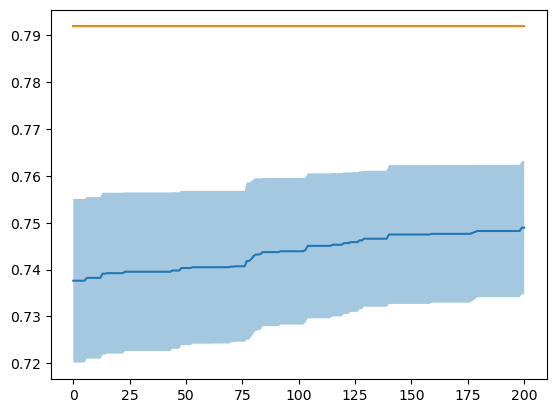

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(data, columns = ['best', 'mean', 'std'])

plt.fill_between(df.index, df['mean']-df['std'], df['mean'] + df['std'], alpha=0.4)
plt.plot(df['mean'])
plt.plot(df['best'])

In [21]:
df.shape

(201, 3)

# Outputs

In [22]:
df_safe = library.molecules
df_safe.head()

,smiles,score
0,COC(=O)CCNC(=O)C1=CCN(c2cc(Cl)cc(Cl)c2)C1,0.791854
1,C=CC(CNC(=O)NCCC(=O)OC)c1cc(Cl)cc(Cl)c1,0.779015
2,COC(=O)CCNC(=O)N1CC(Nc2cc(Cl)cc(Cl)c2)C1,0.774642
3,COC(=O)CCC(=O)CCNC(=O)CC=C1ON(c2cc(Cl)cc(Cl)c2)O1,0.774380
4,C=C(NCCC(=O)OC)c1cc(Cl)cc(Cl)c1,0.768938


In [23]:
len(df_safe)

453

C=CC(CNC(=O)NCCC(=O)OC)c1cc(Cl)cc(Cl)c1


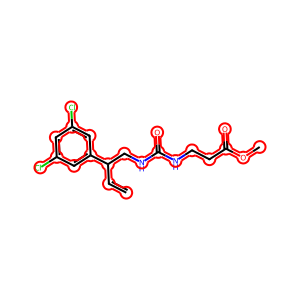

In [24]:
import safe as sf
print(df_safe.iloc[1,0])
sf.to_image(df_safe.iloc[1,0])


In [25]:
len(df_safe)

453

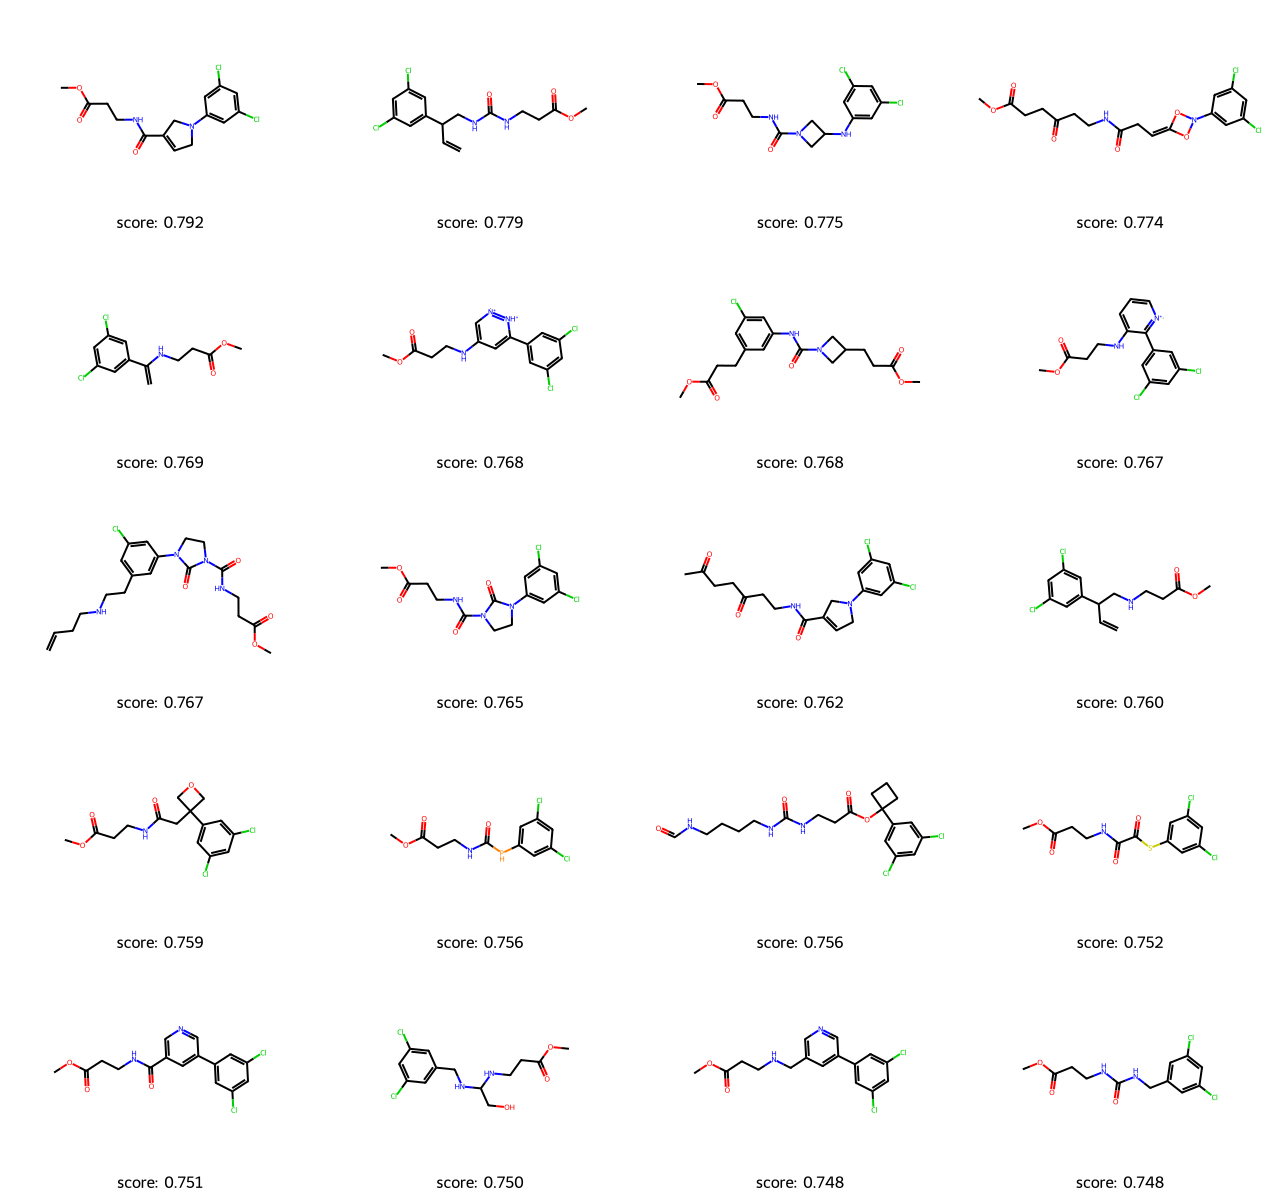

In [26]:
from rdkit.Chem import Draw
from rdkit import Chem
#select first 20
df_to_show = df_safe.iloc[0:20].copy()

#vis
ms = [Chem.MolFromSmiles(row['smiles']) for index, row in df_to_show.iterrows()]
legends = ['score: {:.3f}'.format(row['score']) for index, row in df_to_show.iterrows()]
#['score ' + str(row['score']) for index, row in df_to_show.iterrows()]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(320, 240), legends=legends)


In [27]:
#df_safe.to_csv('../../data/processed/genmol/BCS-CN20332_moo-w-qsar_R2.csv')